# Multithreading on GPU with PoCL-CUDA
This tutorial solves the same problem as the *Multiprocessing on GPU* one: reading several HDF5 files in parallel and performing Bitshuffle-LZ4 decompression and azimuthal integration on the GPUs.
The scale is identical: 1000 files containing 1000 frames each of 4Mpx resolution, i.e. one million frames, reduced to a 1000×1000×1000 single-precision array.

Here **all the workers live in a single process and are threads**, which has several consequences:
- the result array is a plain `numpy` array: no `SharedArray`, no `multiprocess`, no `spawn`, no parameter file to pass the configuration;
- the OpenCL context of a device is created once and shared by all the workers using this device; each worker owns its own command queue and buffers (one `BitshuffleLz4` and one integration engine per worker);
- the heavy work (HDF5 reading, OpenCL calls, `numpy`) releases the GIL, so threads can run concurrently.

**Lenovo P620 Workstation** (same as for the multiprocessing tutorial)
- 1 processor: AMD Threadripper PRO 3975WX, 32 cores with hyperthreading (64 threads) across 4 NUMA sub-domains. 450W TDP.
- 2 GPUs:
  * NVIDIA RTX A5000 (8192 CUDA-cores, 24 GB GDDR6, 16xPCIe4, 230W)
  * NVIDIA Quadro P2200 (1280 CUDA-cores, 5GB GDDR5, 16xPCIe3, 75W)

## Why PoCL-CUDA and not the OpenCL driver of NVIDIA ?
Threads only help if the commands sent to the GPU through *different command queues* can run at the same time. We measured this on the RTX A5000 with the Bitshuffle-LZ4 decompression of Eiger-4M frames (`uint32`, 1.2 MB compressed), one `BitshuffleLz4` per thread, and the OpenCL profiling events to know when the kernels really ran:

| OpenCL implementation | kernels of different queues overlap ? | total throughput with 1 / 2 / 4 / 8 threads (device-side unblocking) |
|---|---|---|
| NVIDIA OpenCL driver | **no** (mean concurrency of 1.00) | 820 / 820 / 811 / 757 fps |
| PoCL-CUDA | **yes** (mean concurrency of 3.9 with 4 threads) | 821 / 1253 / 1630 / 2175 fps |

With the NVIDIA driver, queues are served one after the other: adding threads only adds waiting time, and the performances even decrease. With PoCL-CUDA, the work of the different queues overlaps and the GPU gets saturated, which is what we want. Besides, the profiling events and `clFinish` of the NVIDIA driver are not reliable to measure the time spent when several queues are used in the same process, whereas those of PoCL-CUDA are.

**Requirements:** [PoCL](https://portablecl.org) 4.0 or later, built with its CUDA backend (`-DENABLE_CUDA=ON`) and registered as an OpenCL ICD. The platform is then listed as *Portable Computing Language* and its version string contains `CUDA`. Please note PoCL-CUDA creates a CUDA context on every GPU of the machine when the platform is initialized: the GPUs must not be in the *exclusive-process* compute mode (`nvidia-smi -c DEFAULT`).

Another way to get concurrency with the NVIDIA driver is to use several processes together with the CUDA Multi-Process Service, see the *Multiprocessing on GPU with MPS* tutorial.

Authorization required, but no authorization protocol specified



Exporting format `png' to file `/tmp/topo.png'
Failed to open /tmp/topo.png for writing (File exists)


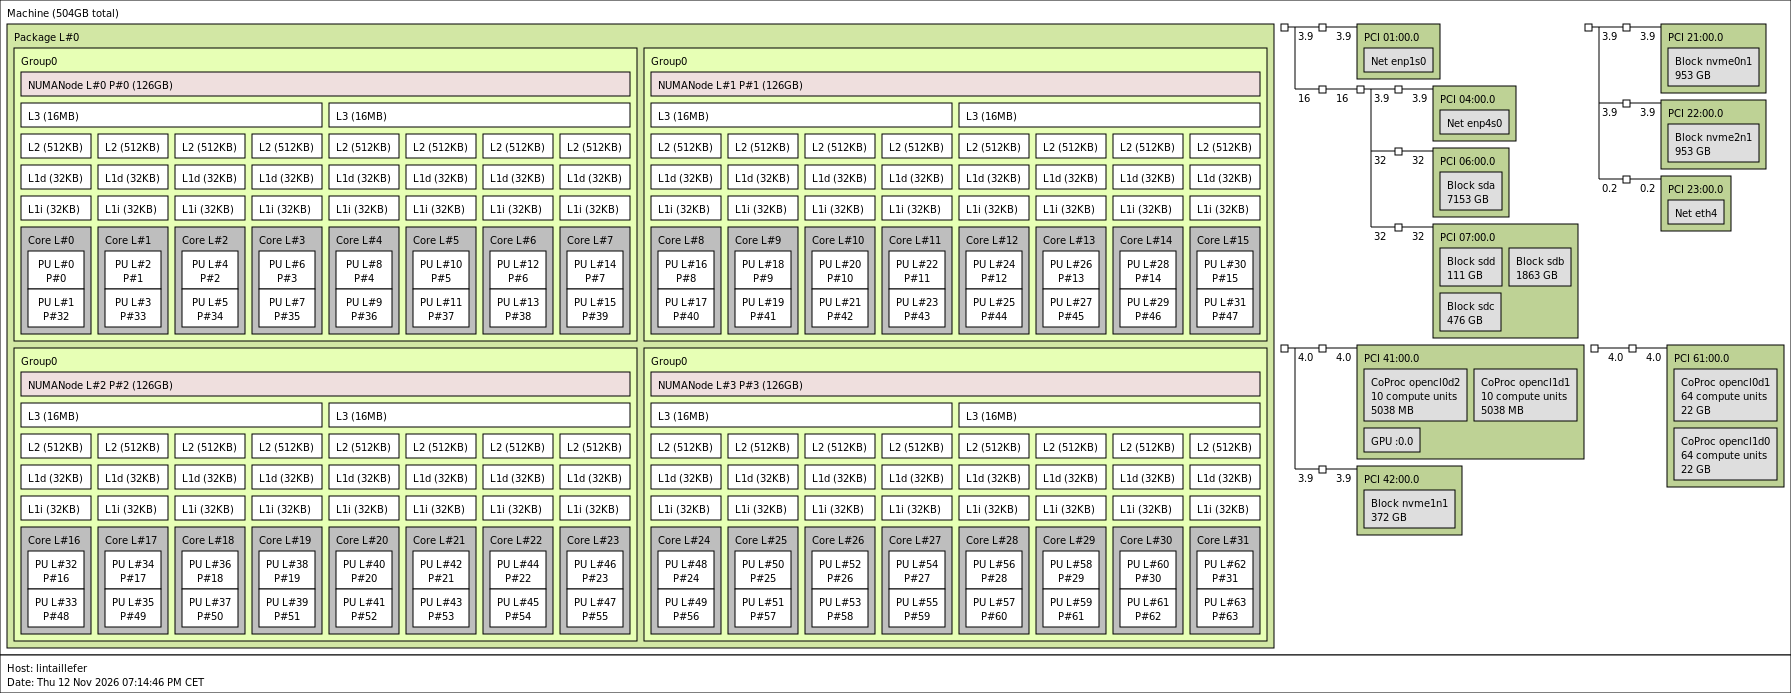

In [1]:
%matplotlib inline
# use `widget` for better user experience; `inline` is for documentation generation

#Topology of the computer:
!lstopo /tmp/topo.png
from IPython.display import Image
Image(filename='/tmp/topo.png') 

In [2]:
%matplotlib inline
import os
import glob
import time
import threading
import queue
import collections
from matplotlib.pyplot import subplots
import numpy
import hdf5plugin
import h5py
import pyFAI
from silx.opencl import ocl
from silx.opencl.codec.bitshuffle_lz4 import BitshuffleLz4
Item = collections.namedtuple("Item", "index filename")
print("pyFAI version: ", pyFAI.version)
print(ocl)

pyFAI version:  2026.9.0
OpenCL devices:
[0] Portable Computing Language: (0,0) cpu-znver2-AMD Ryzen Threadripper PRO 3975WX 32-Cores, (0,1) NVIDIA RTX A5000, (0,2) Quadro P2200
[1] NVIDIA CUDA: (1,0) NVIDIA RTX A5000, (1,1) Quadro P2200
[2] Intel(R) OpenCL: (2,0) AMD Ryzen Threadripper PRO 3975WX 32-Cores


Let's check which OpenCL platform provides the devices we are going to use. The first platform should be PoCL with its CUDA backend (the platform *version* contains `CUDA`), and the NVIDIA GPUs appear there as devices:

In [3]:
import pyopencl
for pid, platform in enumerate(pyopencl.get_platforms()):
    print(pid, platform.name, "|", platform.version)
    for did, device in enumerate(platform.get_devices()):
        print("    ", (pid, did), device.name)

0 Portable Computing Language | OpenCL 3.0 PoCL 4.1-pre main-0-g424ca1ab  Linux, Debug+Asserts, RELOC, SPIR, SPIR-V, LLVM 15.0.6, SLEEF, CUDA, POCL_DEBUG
     (0, 0) cpu-znver2-AMD Ryzen Threadripper PRO 3975WX 32-Cores
     (0, 1) NVIDIA RTX A5000
     (0, 2) Quadro P2200
1 NVIDIA CUDA | OpenCL 3.0 CUDA 12.4.131
     (1, 0) NVIDIA RTX A5000
     (1, 1) Quadro P2200
2 Intel(R) OpenCL | OpenCL 3.0 LINUX
     (2, 0) AMD Ryzen Threadripper PRO 3975WX 32-Cores     


In [4]:
#This cell contains the parameters for all the processing
params = {
    "DEVICES": [[0,1], [0,1],   # 2 threads on the large GPU (PoCL-CUDA)
                [0,2]],         # 1 thread on the small GPU (PoCL-CUDA)
    "NWORKERS": 3,
    "FRAME_PER_FILE": 1000,
    "NFILES" : 1000,
    "NBINS" : 1000,
    "DETECTOR":"Eiger_4M",
    "pathname" : "/tmp/big_%04d.h5",
    "pathmask" : "/tmp/big_????.h5",
    "dtype" : "float32",
    "array_shape" : [1000, 1000, 1000],
    }
for k,v in params.items():
    globals()[k] = v

**Few threads.** Two threads are enough to keep the large GPU busy, and more threads only fight for the GIL (see the conclusion). The small GPU gets a single thread.

**No worker on the CPU-cores here.** The *Multiprocessing* tutorial also used one worker on the CPU through the Intel OpenCL driver. This is a bad idea with threads: the OpenCL runtime of the CPU starts its own pool of threads which occupies (almost) all the cores of the machine (we measured 57 busy cores out of 64), and the Python threads feeding the GPUs get starved. With 6 threads on the large GPU, the throughput falls from 882 fps to 483 fps when a CPU worker is added. In separate processes the operating system arbitrates much better.

In [5]:
def build_integrator(detector=DETECTOR):
    "Build an azimuthal integrator with a dummy geometry"
    geo = {"detector": detector, 
           "wavelength": 1e-10} 
    ai = pyFAI.load(geo)
    return ai

In [6]:
# Generate a set of files
def generate_one_frame(ai, unit="q_nm^-1", dtype="uint32"):
    """Prepare a frame with little count so that it compresses well"""
    qmax = ai.array_from_unit(unit=unit).max()
    q = numpy.linspace(0, qmax, 100)
    img = ai.calcfrom1d(q, 100/(1+q*q))
    frame = numpy.random.poisson(img).astype(dtype)
    return frame

def generate_files(img):
    cmp = hdf5plugin.Bitshuffle()
    filename = pathname%0
    shape = img.shape
    with h5py.File(filename, "w") as h:
        ds = h.create_dataset("data", shape=(FRAME_PER_FILE,)+shape, chunks=(1,)+shape, dtype=img.dtype, **cmp) 
        for i in range(FRAME_PER_FILE):
            ds[i] = img + i%500 #Each frame has a different value to prevent caching effects
    res = [filename]
    for i in range(1, NFILES):
        new_file = pathname%i
        os.link(filename,new_file)
        res.append(new_file)
    return res

# Create a set of files with dummy data in them:
if len(glob.glob(pathmask)) == NFILES: 
    input_files = glob.glob(pathmask)
    input_files.sort()
else:
    for f in glob.glob(pathmask):
        os.remove(f)
    input_files = generate_files(generate_one_frame(build_integrator(DETECTOR)))
input_files[:5]

['/tmp/big_0000.h5',
 '/tmp/big_0001.h5',
 '/tmp/big_0002.h5',
 '/tmp/big_0003.h5',
 '/tmp/big_0004.h5']

## The result array
Threads share the memory of the process: the output is a plain `numpy` array, in which every worker writes its own part (the first index is the number of the file, which is unique for each task).

In [7]:
result_array = numpy.zeros(array_shape, dtype)

## Setting up the workers
The creation of an OpenCL context and of the sparse matrix used for the integration (CSR) is done *once per device* and in the main thread, since it is not meant to be done concurrently. The result is then replicated for each worker by building a new engine from the same sparse matrix (`new_engine`): the matrix is shared in host memory, but every engine gets its own command queue and buffers on the device, as well as its own `BitshuffleLz4`.

In [8]:
def new_engine(engine, wg):
    "Clone an engine (same sparse matrix, same context) with its own queue and a given workgroup size"
    return engine.__class__((engine._data, engine._indices, engine._indptr),
                            engine.size, empty=engine.empty, unit=engine.unit,
                            bin_centers=engine.bin_centers, azim_centers=engine.azim_centers,
                            ctx=engine.ctx, block_size=wg)


def setup_device(device):
    "Build the integrator, solid-angle and base engine for one OpenCL device [platform, device]"
    ai = pyFAI.load({"detector": DETECTOR, "wavelength": 1e-10, "rot3": 0})
    blank = numpy.zeros(ai.detector.shape, dtype="uint32")
    method = ("full", "csr", "opencl", tuple(device))
    res = ai.integrate1d(blank, NBINS, method=method)
    omega = ai.solidAngleArray()
    engine = ai.engines[res.method].engine
    omega_crc = engine.on_device["solidangle"]
    return Setup(engine, omega, omega_crc, blank.shape, blank.dtype)

Setup = collections.namedtuple("Setup", "engine omega omega_crc shape dtype")

t0 = time.perf_counter()
base = {}
for device in DEVICES:
    if tuple(device) not in base:
        base[tuple(device)] = setup_device(device)
print(f"Setup of {len(base)} devices: {time.perf_counter()-t0:.1f}s")

Setup of 2 devices: 2.8s


## The worker
A worker is a function executed by a thread. It takes the name of a file from the input queue, reads the compressed chunks (frames) directly from the HDF5 file, decompresses them on the GPU, integrates them and stores the result. A `None` in the queue is the *kill-pill* ending the worker.

In [9]:
def worker(rank, tasks, setup, ready):
    """Function representing one worker, executed in a thread of the pool.

    :param rank: integer, index of the worker.
    :param tasks: input queue, expects Item with index and name of the file to process
    :param setup: Setup named-tuple with the base engine, solid angle, ... of the device used by this worker
    :param ready: threading.Barrier, reached when the worker is ready to process data
    :return: nothing, the result is written in `result_array`
    """
    engine = new_engine(setup.engine, 512)
    omega, omega_crc = setup.omega, setup.omega_crc
    gpu_decompressor = BitshuffleLz4(2000000, numpy.prod(setup.shape), dtype=setup.dtype, ctx=engine.ctx)
    gpu_decompressor.block_size = 128
    ready.wait()
    #Worker is ready !
    while True:
        item = tasks.get()
        if item is None:
            return
        with h5py.File(item.filename, "r") as h5:
            ds = h5["data"]
            for i in range(ds.id.get_num_chunks()):
                filter_mask, chunk = ds.id.read_direct_chunk(ds.id.get_chunk_info(i).chunk_offset)
                if filter_mask == 0:
                    dec = gpu_decompressor(chunk)
                    intensity = engine.integrate_ng(dec, solidangle=omega, solidangle_checksum=omega_crc).intensity
                    result_array[item.index, i, :] = intensity.astype(dtype)

In [10]:
def build_pool(devices, tasks):
    """Build a pool of threads with workers, and starts them"""
    ready = threading.Barrier(len(devices) + 1)
    pool = []
    for rank, device in enumerate(devices):
        thread = threading.Thread(target=worker, name=f"worker_{rank:02d}", args=(rank, tasks, base[tuple(device)], ready))
        thread.start()
        pool.append(thread)
    ready.wait()  # returns once every worker is up
    return pool

def end_pool(pool, tasks):
    """Ends all threads from a pool by sending them a "kill-pill"""
    for _ in pool:
        tasks.put(None)

# Build the pool of workers
tasks = queue.Queue()
t0 = time.perf_counter()
pool = build_pool(DEVICES[:NWORKERS], tasks)
print(f"{len(pool)} workers ready after {time.perf_counter()-t0:.1f}s")
pool

3 workers ready after 0.4s


/home2/claude/venv/py313/lib/python3.13/site-packages/pyopencl/__init__.py:570: CompilerWarning: Non-empty compiler output encountered. Set the environment variable PYOPENCL_COMPILER_OUTPUT=1 to see more.
  lambda: self._prg.build(options_bytes, devices),


[<Thread(worker_00, started 140538580866752)>,
 <Thread(worker_01, started 140538365945536)>,
 <Thread(worker_02, started 140538321827520)>]

In [11]:
start_time = time.perf_counter()
for idx, fn in enumerate(input_files):
    tasks.put(Item(idx, fn))
end_pool(pool, tasks)
sum(t.is_alive() for t in pool)

3

In [12]:
for thread in pool:
    thread.join()
run_time = time.perf_counter()-start_time
print(f"run-time: {run_time:.1f}s")

run-time: 941.5s


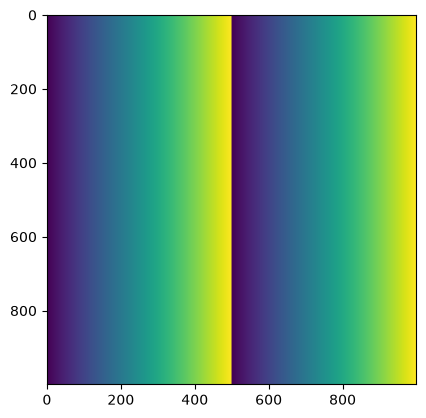

In [13]:
fig, ax = subplots()
ax.imshow(result_array[:,:,5])

In [14]:
print(f"Performances: {NFILES*FRAME_PER_FILE/run_time:.3f} fps")

Performances: 1062.098 fps


## Conclusion
With one process and 3 threads (2 on the large GPU, 1 on the small one), the one million frames are processed in 16 minutes (**1056 frames per second**), whereas the multiprocessing version needs 13 minutes (1306 frames per second, including a worker on the CPU-cores). **For this pipeline, threads are slower than processes, but they get close once the number of threads is kept small.**

The number of threads matters a lot. The same pipeline with more threads is much slower because they compete for the GIL:

| threads | throughput |
|---|---|
| 2 on the RTX A5000 | 997 fps |
| 3 on the RTX A5000 | 982 fps |
| 2 on the RTX A5000 + 1 on the Quadro P2200 (this notebook) | **1056 fps** |
| 6 on the RTX A5000 + 3 on the Quadro P2200 | 732 fps |

The large GPU is already saturated with two threads: a third one brings nothing. The gain of the last configuration comes from the small GPU, which adds about 6%.

The reason is visible in the per-frame work: the LZ4 blocks are located on the host (Cython) and the GPU kernels are short, so most of the time per frame is spent in Python (HDF5 reading, `BitshuffleLz4`, the integration engine) and this part is serialized by the GIL when it runs in a single process. This was checked on the large GPU alone, with the same 6 workers split into a different number of processes (same total number of files, the data are read from memory so that the disk is not involved):

| 6 workers on the RTX A5000 | throughput |
|---|---|
| 1 process × 6 threads | 750 fps |
| 2 processes × 3 threads | 929 fps |
| 3 processes × 2 threads | 980 fps |
| 6 processes × 1 thread | 997 fps |

The throughput increases with the number of processes, which is what one expects when a part of the work is limited by the GIL. In the same way, the HDF5 library is not the bottleneck: reading the chunks directly from memory or with `os.pread` does not change the throughput.

**When are threads a good choice ?**
- When the data are already in the memory of the process, or have to remain there: the result array is a plain `numpy` array, nothing has to be shared, pickled or attached by name.
- When the GPU has a lot of work to overlap and little Python to run between the kernels. For instance, decompressing chunks already on the device with the kernel locating the LZ4 blocks (device-side unblocking) runs at 821 / 1253 / 1630 / 2175 fps with 1 / 2 / 4 / 8 threads in PoCL-CUDA, whereas the NVIDIA driver stays at 820 fps whatever the number of threads.
- When the setup of the workers must be fast: the integrator and its sparse matrix are built once per device (3 seconds here) and cloned for each worker, instead of being rebuilt in each process.

**Practical advice**
- Do not add a worker on the CPU-cores (OpenCL CPU driver) in a threaded application: it starves the Python threads feeding the GPUs.
- Keep the number of threads small (one or two per GPU): more threads do not feed the GPU faster, they only starve each other on the GIL.
- The small GPU (Quadro P2200) is about 7 times slower than the large one. Here it brings little (about 6%): giving it whole files makes the pool wait for it at the end of the run.
- To benefit from both worlds, use several processes, each running a few threads, or the CUDA Multi-Process Service as described in the *Multiprocessing on GPU with MPS* tutorial.